# Flight Price Prediction — End-to-End Machine Learning Project

**Goal:** predict the ticket `price` (₹) of a flight from its airline, route, timing, number of stops, class, duration and how many days before departure it was booked.

**Notebook outline**
1. Problem & dataset
2. Exploratory Data Analysis (EDA)
3. Data preprocessing & feature engineering
4. Model experimentation (7 models)
5. Model record & comparison
6. Best model → Kaggle submission
7. Final report summary

## 0. Setup

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

## 1. Problem and Dataset

In [2]:
train = pd.read_csv("train.csv")
test  = pd.read_csv("test.csv")
sample_sub = pd.read_csv("sample_submission.csv")

print("Train shape:", train.shape)
print("Test shape :", test.shape)
train.head()

Train shape: (15589, 12)
Test shape : (3898, 11)


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,1,Wayfarer Aviation,IX 1070,Metropolis,Evening,zero,Night,Springfield,Economy,NaN,18,8909
1,2,Oceanic Airlines,6E 285,Los Santos,Night,zero,Night,Springfield,Economy,1.33,38,5115
2,3,Wayfarer Aviation,AI 2641,Night City,Evening,zero,Night,Springfield,Business,2.08,13,35247
3,4,Oceanic Airlines,6E 6704,Night City,Afternoon,zero,Evening,Metropolis,Economy,2.25,5,6457
4,5,Oceanic Airlines,6E 234,Hill Valley,Evening,one,Night,Springfield,Economy,4.83,21,6842


In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 15589 entries, 0 to 15588
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                15589 non-null  int64  
 1   airline           12500 non-null  str    
 2   flight            15589 non-null  str    
 3   source_city       15589 non-null  str    
 4   departure_time    15589 non-null  str    
 5   stops             15589 non-null  str    
 6   arrival_time      15589 non-null  str    
 7   destination_city  15589 non-null  str    
 8   flight_class      15589 non-null  str    
 9   duration          12494 non-null  float64
 10  days_left         15589 non-null  int64  
 11  price             15589 non-null  int64  
dtypes: float64(1), int64(3), str(8)
memory usage: 1.4 MB


In [4]:
train.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,15589.0,NaN,NaN,NaN,7795.0,4500.301008,1.0,3898.0,7795.0,11692.0,15589.0
airline,12500,18,Wayfarer Aviation,5200,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flight,15589,1070,AI 441,88,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source_city,15589,6,Metropolis,6198,NaN,NaN,NaN,NaN,NaN,NaN,NaN
departure_time,15589,6,Evening,3304,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stops,15589,3,zero,10965,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_time,15589,6,Night,3845,NaN,NaN,NaN,NaN,NaN,NaN,NaN
destination_city,15589,6,Night City,4663,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flight_class,15589,2,Economy,9209,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,12494.0,NaN,NaN,NaN,4.300499,4.181832,0.92,2.25,2.5,4.92,38.08


**Dataset description**

| Column | Type | Meaning |
|---|---|---|
| `airline` | categorical | Operating airline |
| `flight` | categorical | Flight code, e.g. `6E 285` (prefix = carrier code) |
| `source_city`, `destination_city` | categorical | 6 cities each |
| `departure_time`, `arrival_time` | categorical | Time-of-day bucket (6 levels) |
| `stops` | ordinal | `zero`, `one`, `two_or_more` |
| `flight_class` | binary | Economy / Business |
| `duration` | numeric | Flight duration in hours |
| `days_left` | numeric | Days between booking and departure |
| `price` | **target** | Ticket price in ₹ |

This is a **supervised regression** problem. Train has 15,589 rows and test has 3,898 rows.

## 2. Exploratory Data Analysis

### 2.1 Missing values and duplicates

In [5]:
miss = pd.DataFrame({
    "train_missing": train.isna().sum(),
    "train_%": (train.isna().mean() * 100).round(2),
    "test_missing": test.isna().sum().reindex(train.columns),
})
display(miss[miss.train_missing.add(miss.test_missing.fillna(0)) > 0])

dups = train.drop(columns=["id"]).duplicated().sum()
print("Exact duplicate rows (excluding id):", dups)

,train_missing,train_%,test_missing
airline,3089,19.82,799.0
duration,3095,19.85,776.0


Exact duplicate rows (excluding id): 279


### 2.2 Target variable: `price`

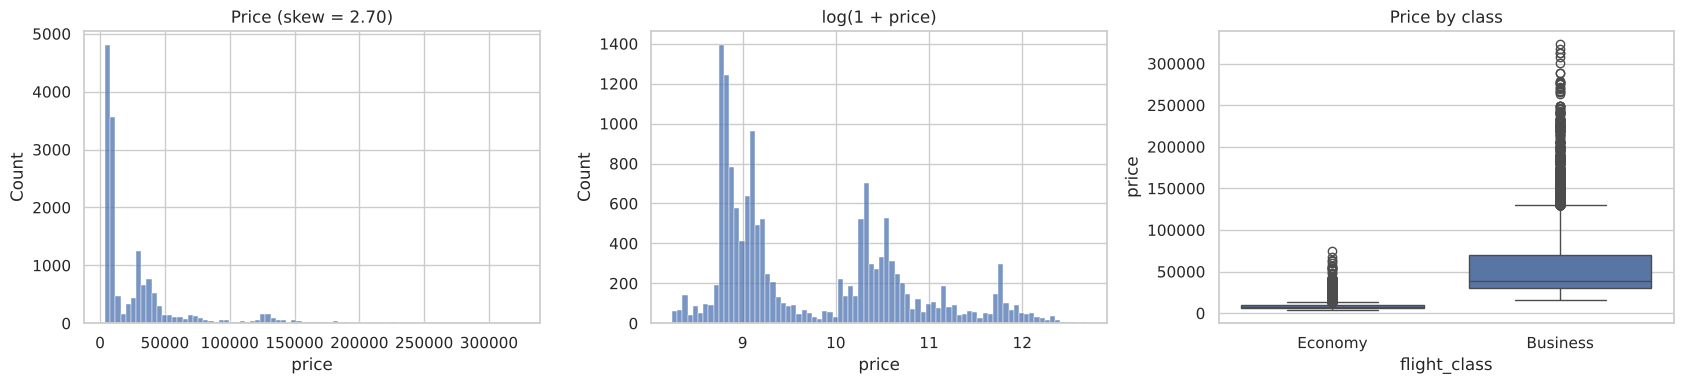

,count,mean,std,min,25%,50%,75%,max
flight_class,,,,,,,,
Business,6380.0,60127.0,46415.0,15544.0,30767.0,38546.0,70441.0,323177.0
Economy,9209.0,8818.0,4670.0,3801.0,6740.0,7587.0,9340.0,74691.0


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(train.price, bins=80, ax=ax[0]); ax[0].set_title(f"Price (skew = {train.price.skew():.2f})")
sns.histplot(np.log1p(train.price), bins=80, ax=ax[1]); ax[1].set_title("log(1 + price)")
sns.boxplot(data=train, x="flight_class", y="price", ax=ax[2]); ax[2].set_title("Price by class")
plt.tight_layout(); plt.show()

train.groupby("flight_class").price.describe().round(0)

### 2.3 Categorical features vs price

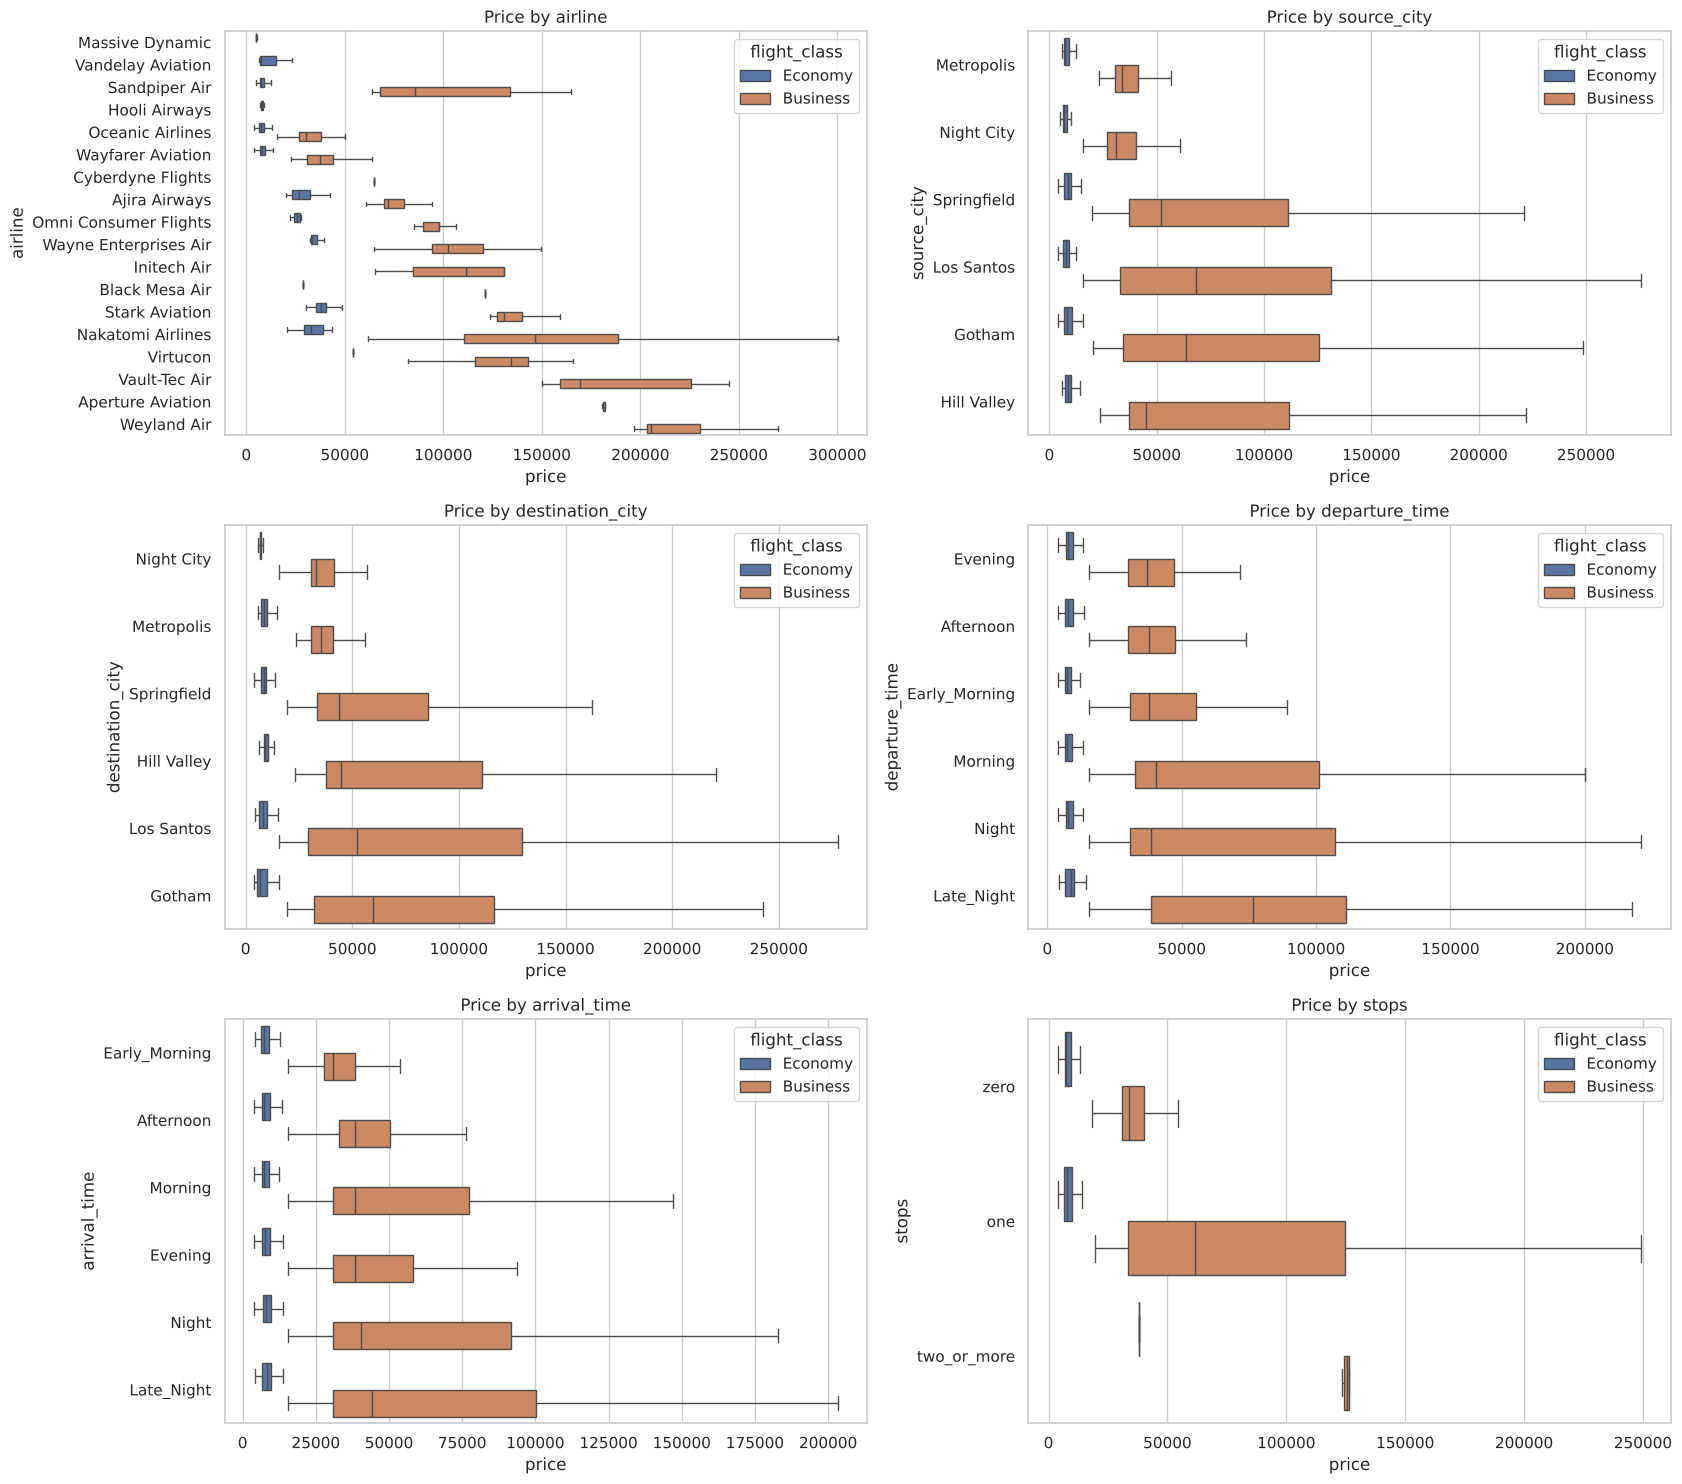

In [7]:
cats = ["airline", "source_city", "destination_city", "departure_time", "arrival_time", "stops"]
fig, axes = plt.subplots(3, 2, figsize=(17, 15))
for ax, c in zip(axes.ravel(), cats):
    order = train.groupby(c).price.median().sort_values().index
    sns.boxplot(data=train, y=c, x="price", hue="flight_class", order=order, ax=ax, showfliers=False)
    ax.set_title(f"Price by {c}")
plt.tight_layout(); plt.show()

In [8]:
for c in cats + ["flight_class"]:
    vc = train[c].value_counts(dropna=False)
    print(f"{c}: {train[c].nunique()} levels  ->", dict(vc.head(8)))

airline: 18 levels  -> {'Wayfarer Aviation': np.int64(5200), 'Oceanic Airlines': np.int64(5112), nan: np.int64(3089), 'Sandpiper Air': np.int64(697), 'Stark Aviation': np.int64(336), 'Ajira Airways': np.int64(330), 'Nakatomi Airlines': np.int64(319), 'Wayne Enterprises Air': np.int64(180)}
source_city: 6 levels  -> {'Metropolis': np.int64(6198), 'Night City': np.int64(2651), 'Springfield': np.int64(2051), 'Hill Valley': np.int64(1600), 'Gotham': np.int64(1586), 'Los Santos': np.int64(1503)}
destination_city: 6 levels  -> {'Night City': np.int64(4663), 'Springfield': np.int64(2870), 'Metropolis': np.int64(2759), 'Hill Valley': np.int64(2126), 'Los Santos': np.int64(1609), 'Gotham': np.int64(1562)}
departure_time: 6 levels  -> {'Evening': np.int64(3304), 'Morning': np.int64(3296), 'Night': np.int64(2832), 'Early_Morning': np.int64(2680), 'Afternoon': np.int64(2462), 'Late_Night': np.int64(1015)}
arrival_time: 6 levels  -> {'Night': np.int64(3845), 'Morning': np.int64(3116), 'Evening': np

In [9]:
train.groupby('airline').price.agg(['count', 'median']).sort_values('median').round(0)

,count,median
airline,,
Massive Dynamic,2,5084.0
Vandelay Aviation,115,7719.0
Sandpiper Air,697,7851.0
Hooli Airways,2,8060.0
Oceanic Airlines,5112,8759.0
Wayfarer Aviation,5200,14200.0
Cyberdyne Flights,2,65005.0
Ajira Airways,330,71716.0
Omni Consumer Flights,24,96549.0


### 2.4 Numeric features vs price

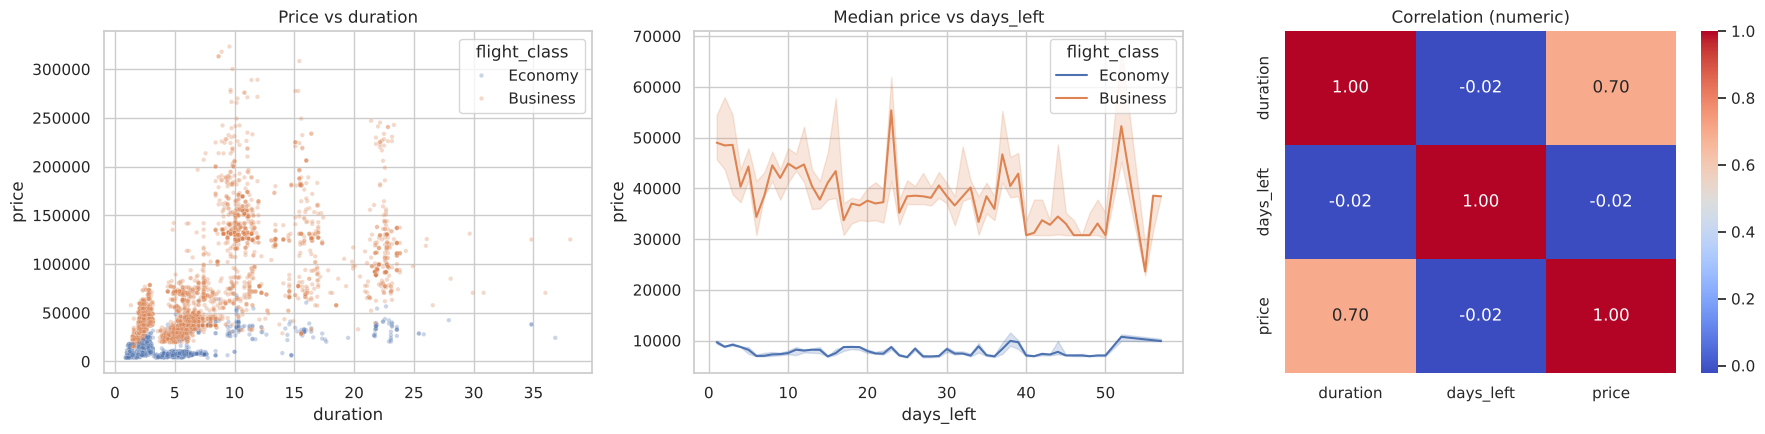

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
sns.scatterplot(data=train, x="duration", y="price", hue="flight_class", alpha=.3, s=10, ax=ax[0])
ax[0].set_title("Price vs duration")
sns.lineplot(data=train, x="days_left", y="price", hue="flight_class", estimator="median", ax=ax[1])
ax[1].set_title("Median price vs days_left")
sns.heatmap(train[["duration", "days_left", "price"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[2])
ax[2].set_title("Correlation (numeric)")
plt.tight_layout(); plt.show()

### 2.5 Routes and the `flight` code

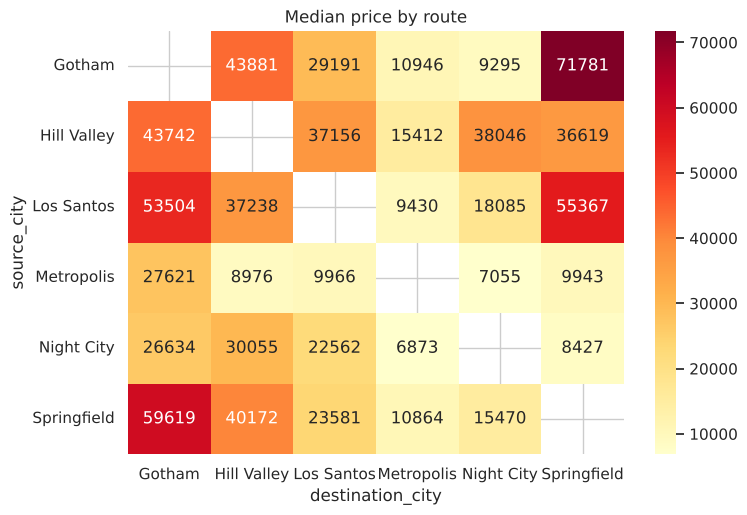

Flight prefixes: 19 | share of prefixes that map to exactly one airline: 1.0
Unique flight codes: 1070 | test flight codes seen in train: 0.991


In [11]:
plt.figure(figsize=(8, 5.5))
sns.heatmap(train.pivot_table(index="source_city", columns="destination_city", values="price", aggfunc="median"),
            annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("Median price by route"); plt.show()

train["_prefix"] = train.flight.str.split().str[0]
purity = train.dropna(subset=["airline"]).groupby("_prefix").airline.agg(lambda s: s.value_counts(normalize=True).iloc[0])
print("Flight prefixes:", train._prefix.nunique(), "| share of prefixes that map to exactly one airline:", (purity == 1).mean())
print("Unique flight codes:", train.flight.nunique(), "| test flight codes seen in train:", round(test.flight.isin(train.flight).mean(), 3))
train.drop(columns="_prefix", inplace=True)

### 2.6 Key EDA observations

1. **Missing data:** `airline` (~20%) and `duration` (~20%) are missing in both train and test. No other column has gaps. 279 rows are exact duplicates on all features + price; they are kept because identical tickets can genuinely be sold at the same price.
2. **Target is heavily right-skewed** (skew ≈ 2.7, range ₹3.8k–₹323k). The distribution is **bimodal**, driven almost entirely by `flight_class`: Business median ≈ ₹38.5k vs Economy ≈ ₹7.6k.
3. **Two groups of airlines:** domestic carriers (Oceanic, Wayfarer, Sandpiper, Vandelay…) have median prices ₹5k–₹14k, while the low-volume premium/international carriers (Stark, Nakatomi, Virtucon, Weyland…) sit at ₹65k–₹200k. Airline is a very strong signal.
4. **Stops:** more stops → higher price (zero ≈ ₹8.9k, one ≈ ₹40.5k, two+ ≈ ₹126k median), partly because multi-stop flights are longer and more often premium carriers.
5. **Duration** has the strongest numeric correlation with price (r ≈ 0.70), but the relationship differs by class, so a duration-only model will be poor.
6. **days_left** is non-linear: Economy fares jump sharply in the last ~3 days before departure and are flat beyond ~2 weeks. Linear correlation is ~0, so tree models / polynomial terms should capture it better than a straight line.
7. **`Late_Night` departures** are much pricier (median ≈ ₹33k) than other slots (≈ ₹9–11k).
8. **Flight code prefix (e.g. `6E`, `AI`) maps 1-to-1 to an airline** → it can be used to recover the missing `airline` values exactly. 99% of test flight codes appear in train.

## 3. Data Preprocessing

| Step | What | Why |
|---|---|---|
| 1 | Extract `flight_prefix` from `flight` | Carrier code; deterministic proxy for airline |
| 2 | Impute missing `airline` from the prefix → airline mapping (fallback `Unknown`) | Prefix maps to exactly one airline, so imputation is lossless |
| 3 | Impute `duration` with hierarchical medians: same flight + route + stops → same route + stops → same stops | A given flight on a given route has a near-constant duration; much better than a global mean |
| 4 | Encode `stops` ordinally (0, 1, 2) and `flight_class` as binary `is_business` | Both have a natural order / two levels |
| 5 | Create `route` = source_destination | Price depends on the city pair, not each city independently |
| 6 | One-hot encode nominal features (rare levels < 5 rows grouped) | Linear models need numeric inputs; grouping rare levels limits overfitting |
| 7 | Standard-scale numeric features (linear models only) | Needed so Ridge/Lasso penalties treat coefficients fairly; trees don't need scaling |
| 8 | Drop `id` and raw `flight` | `id` is an index; raw flight code has ~1,000 levels and is summarised by prefix |

All imputation statistics are learned from **train only** and applied to test, so no information leaks from test.

In [12]:
def preprocess(df, ref):
    """Clean + engineer features for df, using statistics learned from ref (training data)."""
    df = df.copy()
    ref_prefix = ref.flight.str.split().str[0]
    df["flight_prefix"] = df.flight.str.split().str[0]

    # airline imputation from prefix
    prefix_to_airline = ref.dropna(subset=["airline"]).groupby(ref_prefix).airline.agg(lambda s: s.mode()[0])
    df["airline"] = df.airline.fillna(df.flight_prefix.map(prefix_to_airline)).fillna("Unknown")

    # hierarchical duration imputation
    for keys in [["flight", "source_city", "destination_city", "stops"],
                 ["source_city", "destination_city", "stops"],
                 ["stops"]]:
        med = ref.groupby(keys).duration.median().rename("_med")
        df = df.merge(med, left_on=keys, right_index=True, how="left")
        df["duration"] = df.duration.fillna(df._med)
        df = df.drop(columns="_med")

    df["stops_num"] = df.stops.map({"zero": 0, "one": 1, "two_or_more": 2})
    df["is_business"] = (df.flight_class == "Business").astype(int)
    df["route"] = df.source_city + "_" + df.destination_city
    return df

train_p = preprocess(train, train)
test_p  = preprocess(test, train)

CAT = ["airline", "flight_prefix", "source_city", "destination_city", "route", "departure_time", "arrival_time"]
NUM = ["duration", "days_left", "stops_num", "is_business"]

print("Missing after preprocessing  train:", train_p[CAT + NUM].isna().sum().sum(), "| test:", test_p[CAT + NUM].isna().sum().sum())
print("Airline still 'Unknown' in train:", (train_p.airline == "Unknown").sum(), "| test:", (test_p.airline == "Unknown").sum())
train_p[CAT + NUM + ["price"]].head()

Missing after preprocessing  train: 0 | test: 0
Airline still 'Unknown' in train: 0 | test: 0


,airline,flight_prefix,source_city,destination_city,route,departure_time,arrival_time,duration,days_left,stops_num,is_business,price
0,Wayfarer Aviation,IX,Metropolis,Springfield,Metropolis_Springfield,Evening,Night,2.92,18,0,0,8909
1,Oceanic Airlines,6E,Los Santos,Springfield,Los Santos_Springfield,Night,Night,1.33,38,0,0,5115
2,Wayfarer Aviation,AI,Night City,Springfield,Night City_Springfield,Evening,Night,2.08,13,0,1,35247
3,Oceanic Airlines,6E,Night City,Metropolis,Night City_Metropolis,Afternoon,Evening,2.25,5,0,0,6457
4,Oceanic Airlines,6E,Hill Valley,Springfield,Hill Valley_Springfield,Evening,Night,4.83,21,1,0,6842


### Validation strategy
An 80/20 hold-out split (fixed seed) is used to compare all models on the same unseen data. Metrics reported for each model: **R²**, **MAE** and **RMSE** (₹). Hyperparameters for Lasso, polynomial, decision tree and random forest are chosen with **cross-validation on the training part only**, so the hold-out set stays untouched.

In [13]:
X = train_p[CAT + NUM]
y = train_p["price"]
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(X_tr.shape, X_val.shape)

def make_preprocessor(scale=True):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), CAT),
        ("num", StandardScaler() if scale else "passthrough", NUM),
    ])

results = []
def evaluate(name, model, notes=""):
    t0 = time.time()
    model.fit(X_tr, y_tr)
    pred = model.predict(X_val)
    secs = time.time() - t0
    row = {"Model": name,
           "R2": r2_score(y_val, pred),
           "MAE": mean_absolute_error(y_val, pred),
           "RMSE": mean_squared_error(y_val, pred) ** 0.5,
           "Train time (s)": round(secs, 1),
           "Notes": notes}
    results.append(row)
    print(f"{name:45s} R2={row['R2']:.4f}  MAE=₹{row['MAE']:,.0f}  RMSE=₹{row['RMSE']:,.0f}  ({secs:.1f}s)")
    return model, pred

(12471, 11) (3118, 11)


## 4. Model Experimentation

### Model 1 — Simple linear regression (duration only)

In [14]:
slr = Pipeline([("sel", ColumnTransformer([("d", "passthrough", ["duration"])])),
                ("lr", LinearRegression())])
slr, p_slr = evaluate("Simple linear regression (duration only)", slr, "Single predictor baseline")
print("Coefficient: ₹%.0f per hour, intercept ₹%.0f" % (slr[-1].coef_[0], slr[-1].intercept_))

Simple linear regression (duration only)      R2=0.4959  MAE=₹17,482  RMSE=₹26,655  (0.0s)
Coefficient: ₹6716 per hour, intercept ₹1279


*Observation:* duration alone explains only about half the variance. It cannot tell Economy from Business, so short Business flights and long Economy flights are both badly mispredicted. This sets the baseline every other model must beat.

### Model 2 — Multiple linear regression (all features)

In [15]:
mlr = Pipeline([("prep", make_preprocessor()), ("lr", LinearRegression())])
mlr, p_mlr = evaluate("Multiple linear regression (all features)", mlr, "All one-hot + scaled numeric")

Multiple linear regression (all features)     R2=0.8558  MAE=₹7,410  RMSE=₹14,255  (0.1s)


*Observation:* adding class, airline, route and timing lifts R² to ~0.86 — a huge jump, confirming that `flight_class` and `airline` carry most of the signal. But a linear model can't capture the non-linear `days_left` curve or interactions such as "Business × premium airline", so errors on expensive tickets remain large.

### Model 3 — Polynomial regression (degree 2)

In [16]:
poly_pipe = Pipeline([("prep", make_preprocessor()),
                      ("poly", PolynomialFeatures(degree=2, include_bias=False)),
                      ("reg", Ridge())])
poly_grid = GridSearchCV(poly_pipe, {"reg__alpha": [0.1, 1, 5, 20]},
                         cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="r2", n_jobs=-1)
poly_grid.fit(X_tr, y_tr)
print("Best alpha:", poly_grid.best_params_, "| CV R2:", round(poly_grid.best_score_, 4))
poly, p_poly = evaluate("Polynomial regression (degree 2)", poly_grid.best_estimator_,
                        f"All pairwise interactions + Ridge alpha={poly_grid.best_params_['reg__alpha']}")

Best alpha: {'reg__alpha': 20} | CV R2: 0.9182


Polynomial regression (degree 2)              R2=0.9261  MAE=₹4,616  RMSE=₹10,205  (0.3s)


*Observation:* degree-2 terms add interactions (class × duration, class × airline, days_left²) and give a clear gain over plain linear regression. Thousands of interaction features are created, so a small Ridge penalty is used to keep it stable; without it the fit overfits.

### Model 4 — Ridge regression (L2)

In [17]:
ridge_grid = GridSearchCV(Pipeline([("prep", make_preprocessor()), ("reg", Ridge())]),
                          {"reg__alpha": [0.1, 1, 5, 10, 50]},
                          cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="r2")
ridge_grid.fit(X_tr, y_tr)
print("Best alpha:", ridge_grid.best_params_)
ridge, p_ridge = evaluate("Ridge regression", ridge_grid.best_estimator_, f"alpha={ridge_grid.best_params_['reg__alpha']}")

Best alpha: {'reg__alpha': 5}
Ridge regression                              R2=0.8561  MAE=₹7,424  RMSE=₹14,241  (0.1s)


*Observation:* Ridge performs essentially the same as multiple linear regression. The model is **under-fitting (high bias), not over-fitting**, so shrinking coefficients doesn't help — we need a more flexible model, not more regularisation.

### Model 5 — Lasso regression (L1)

In [18]:
lasso_grid = GridSearchCV(Pipeline([("prep", make_preprocessor()), ("reg", Lasso(max_iter=20000))]),
                          {"reg__alpha": [0.001, 1, 10, 50]},
                          cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="r2", n_jobs=-1)
lasso_grid.fit(X_tr, y_tr)
print("Best alpha:", lasso_grid.best_params_)
lasso, p_lasso = evaluate("Lasso regression", lasso_grid.best_estimator_, f"alpha={lasso_grid.best_params_['reg__alpha']}")
coef = lasso[-1].coef_
print(f"Non-zero coefficients: {(coef != 0).sum()} / {len(coef)}")

Best alpha: {'reg__alpha': 10}


Lasso regression                              R2=0.8567  MAE=₹7,353  RMSE=₹14,209  (0.4s)
Non-zero coefficients: 70 / 91


*Observation:* Lasso matches Ridge/MLR. It zeroes out a few redundant dummies (e.g. route vs source/destination overlap), which is useful for interpretability but not for accuracy — same high-bias limitation.

### Model 6 — Decision tree

Best params: {'dt__max_depth': 10, 'dt__min_samples_leaf': 3} | CV R2: 0.9068
Decision tree                                 R2=0.9202  MAE=₹3,892  RMSE=₹10,605  (0.2s)


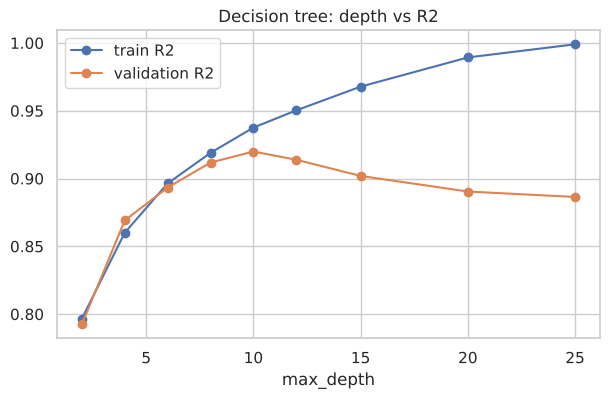

In [19]:
dt_grid = GridSearchCV(Pipeline([("prep", make_preprocessor(scale=False)),
                                 ("dt", DecisionTreeRegressor(random_state=RANDOM_STATE))]),
                       {"dt__max_depth": [10, 15, 20, None], "dt__min_samples_leaf": [1, 3, 5, 10]},
                       cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="r2", n_jobs=-1)
dt_grid.fit(X_tr, y_tr)
print("Best params:", dt_grid.best_params_, "| CV R2:", round(dt_grid.best_score_, 4))
dt, p_dt = evaluate("Decision tree", dt_grid.best_estimator_, str(dt_grid.best_params_))

# depth vs performance — shows the bias/variance trade-off
depth_scores = []
for d in [2, 4, 6, 8, 10, 12, 15, 20, 25]:
    m = Pipeline([("prep", make_preprocessor(scale=False)), ("dt", DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE))]).fit(X_tr, y_tr)
    depth_scores.append((d, r2_score(y_tr, m.predict(X_tr)), r2_score(y_val, m.predict(X_val))))
ds = pd.DataFrame(depth_scores, columns=["max_depth", "train R2", "validation R2"]).set_index("max_depth")
ds.plot(marker="o", figsize=(7, 4), title="Decision tree: depth vs R2"); plt.show()

*Observation:* a tree handles non-linearity and interactions automatically and gives the lowest MAE so far. However, train R² rises toward 1.0 as depth grows while validation R² flattens/drops — a single deep tree **overfits**. Limiting depth / leaf size is essential.

### Model 7 — Random forest

In [20]:
rf_grid = GridSearchCV(Pipeline([("prep", make_preprocessor(scale=False)),
                                 ("rf", RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE))]),
                       {"rf__max_features": [0.3, 0.5, 1.0], "rf__min_samples_leaf": [1, 2, 4]},
                       cv=KFold(3, shuffle=True, random_state=RANDOM_STATE), scoring="r2")
rf_grid.fit(X_tr, y_tr)
print("Best params:", rf_grid.best_params_, "| CV R2:", round(rf_grid.best_score_, 4))

best_rf = rf_grid.best_estimator_.set_params(rf__n_estimators=400)
rf, p_rf = evaluate("Random forest", best_rf, f"400 trees, {rf_grid.best_params_}")

Best params: {'rf__max_features': 0.3, 'rf__min_samples_leaf': 2} | CV R2: 0.9282


Random forest                                 R2=0.9362  MAE=₹3,193  RMSE=₹9,486  (21.5s)


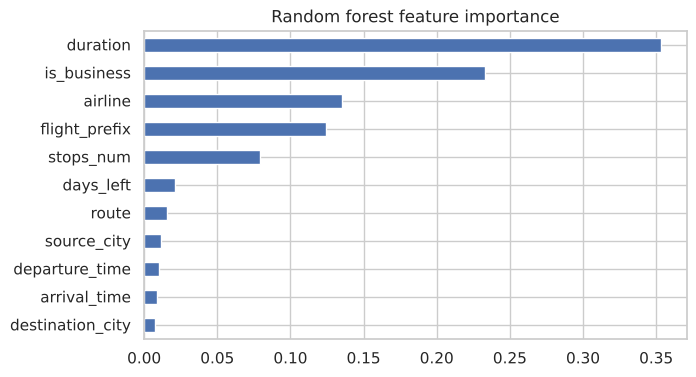

In [21]:
# Feature importance (aggregated back to original columns)
names = rf[0].get_feature_names_out()
imp = pd.Series(rf[-1].feature_importances_, index=names)
orig = imp.groupby(lambda n: next(c for c in CAT + NUM if n.split("__", 1)[1].startswith(c))).sum().sort_values()
orig.plot.barh(figsize=(7, 4), title="Random forest feature importance"); plt.show()

*Observation:* averaging many de-correlated trees removes most of the single tree's variance and gives the best R², MAE and RMSE. Feature importance confirms the EDA: `is_business` dominates, followed by duration/airline and days_left. It is the slowest model to train, but still fast enough for this dataset size.

## 5. Model Record and Comparison

In [22]:
res = (pd.DataFrame(results)
         .sort_values("R2", ascending=False)
         .reset_index(drop=True))
res.index += 1
res_fmt = res.copy()
res_fmt["R2"] = res_fmt.R2.round(4)
res_fmt["MAE"] = res_fmt.MAE.map("₹{:,.0f}".format)
res_fmt["RMSE"] = res_fmt.RMSE.map("₹{:,.0f}".format)
res_fmt

,Model,R2,MAE,RMSE,Train time (s),Notes
1,Random forest,0.9362,"₹3,193","₹9,486",21.5,"400 trees, {'rf__max_features': 0.3, 'rf__min_..."
2,Polynomial regression (degree 2),0.9261,"₹4,616","₹10,205",0.3,All pairwise interactions + Ridge alpha=20
3,Decision tree,0.9202,"₹3,892","₹10,605",0.2,"{'dt__max_depth': 10, 'dt__min_samples_leaf': 3}"
4,Lasso regression,0.8567,"₹7,353","₹14,209",0.4,alpha=10
5,Ridge regression,0.8561,"₹7,424","₹14,241",0.1,alpha=5
6,Multiple linear regression (all features),0.8558,"₹7,410","₹14,255",0.1,All one-hot + scaled numeric
7,Simple linear regression (duration only),0.4959,"₹17,482","₹26,655",0.0,Single predictor baseline


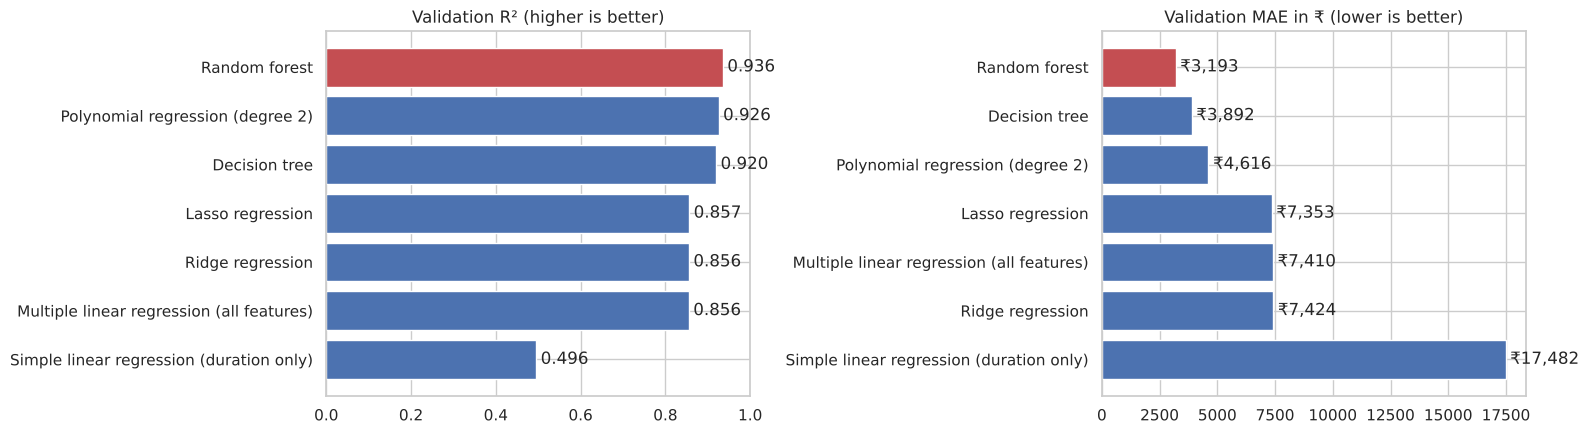

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
r = res.sort_values("R2")
ax[0].barh(r.Model, r.R2.clip(lower=0), color=["#c44e52" if m == res.Model.iloc[0] else "#4c72b0" for m in r.Model])
ax[0].set_title("Validation R² (higher is better)"); ax[0].set_xlim(0, 1)
for i, v in enumerate(r.R2): ax[0].text(max(v, 0) + .01, i, f"{v:.3f}", va="center")
r = res.sort_values("MAE", ascending=False)
ax[1].barh(r.Model, r.MAE, color=["#c44e52" if m == res.Model.iloc[0] else "#4c72b0" for m in r.Model])
ax[1].set_title("Validation MAE in ₹ (lower is better)")
for i, v in enumerate(r.MAE): ax[1].text(v + 200, i, f"₹{v:,.0f}", va="center")
plt.tight_layout(); plt.show()

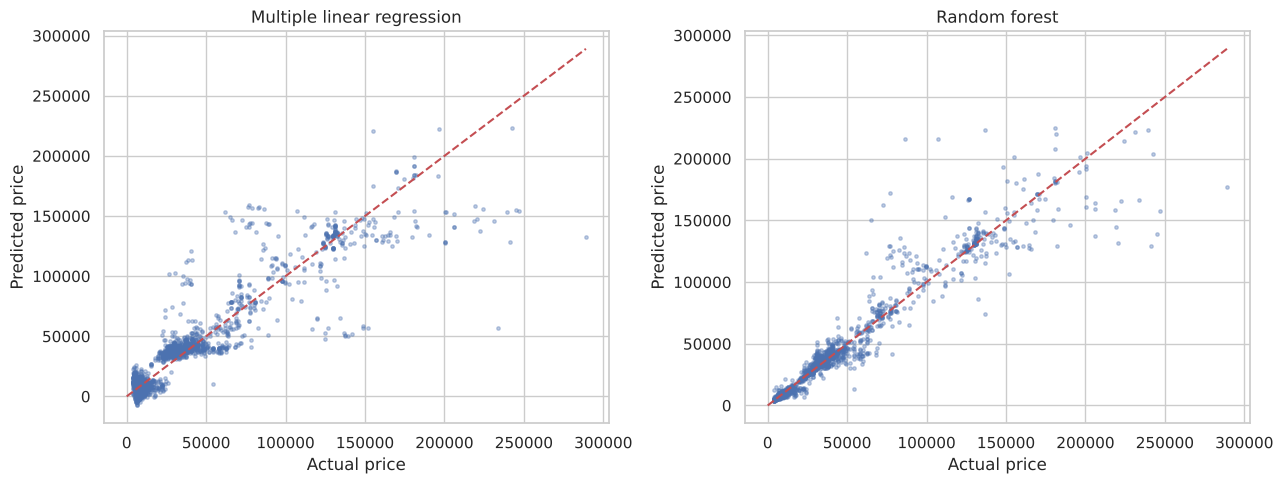

In [24]:
# Predicted vs actual for the best linear model and the best tree model
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, (nm, p) in zip(ax, [("Multiple linear regression", p_mlr), ("Random forest", p_rf)]):
    a.scatter(y_val, p, s=6, alpha=.35)
    lim = [0, y_val.max()]
    a.plot(lim, lim, "r--"); a.set_xlabel("Actual price"); a.set_ylabel("Predicted price"); a.set_title(nm)
plt.tight_layout(); plt.show()

### Discussion

* **Baseline → full linear:** going from duration only to all features is the biggest single improvement; most of the predictive power lives in the categorical features (class, airline, route).
* **Regularisation didn't help** (Ridge ≈ Lasso ≈ MLR). With ~15k rows and ~70 features the linear model is not overfitting; its errors come from bias.
* **Adding non-linearity is what matters.** Polynomial features, a decision tree and a random forest all beat every linear model because price depends on interactions (Business × premium carrier, last-minute × Economy) and on a non-linear `days_left` curve.
* **Single tree vs forest:** the single tree overfits as it grows deeper; bagging + random feature subsets in the forest cut the RMSE further and gave the best overall scores.
* **Remaining error** is concentrated in the very expensive tickets (₹100k+), which are rare premium-carrier fares — visible in the predicted-vs-actual plot spreading out at the top end.

## 6. Best Model → Kaggle Submission

In [25]:
best_name = res.Model.iloc[0]
print("Best model on validation:", best_name)

# 5-fold CV of the final configuration on the full training set, for a more stable estimate
final_model = rf_grid.best_estimator_.set_params(rf__n_estimators=400)
cv = cross_val_score(final_model, X, y, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="r2")
print("5-fold CV R2 on full train: %.4f ± %.4f" % (cv.mean(), cv.std()))

# Refit on ALL training data, then predict test
final_model.fit(X, y)
test_pred = final_model.predict(test_p[CAT + NUM])

submission = pd.DataFrame({"id": test.id, "price": test_pred})
assert len(submission) == len(sample_sub) and (submission.id.values == sample_sub.id.values).all()
submission.to_csv("submission.csv", index=False)
print(submission.shape); submission.head()

Best model on validation: Random forest


5-fold CV R2 on full train: 0.9319 ± 0.0045


(3898, 2)


,id,price
0,1,8512.429340
1,2,7295.802061
2,3,29625.916615
3,4,33094.027772
4,5,4761.330724


In [26]:
submission.price.describe().round(0)

count      3898.0
mean      29741.0
std       38223.0
min        3905.0
25%        7334.0
50%       10170.0
75%       36185.0
max      233952.0
Name: price, dtype: float64

## 7. Final Report Summary

**1. Problem and dataset.** Regression task: predict flight ticket price (₹) from 10 features (airline, flight code, source/destination city, departure/arrival time bucket, stops, class, duration, days_left). 15,589 training rows, 3,898 test rows.

**2. EDA.** Price is right-skewed and bimodal because of class (Business ≈ 5× Economy). Airlines split into cheap domestic and expensive premium carriers. Duration is the strongest numeric correlate (r ≈ 0.70). `days_left` has a non-linear last-minute spike for Economy. ~20% of `airline` and `duration` values are missing. The flight-code prefix maps one-to-one to airline.

**3. Preprocessing.** Airline imputed from flight prefix (lossless); duration imputed with hierarchical medians (flight+route+stops → route+stops → stops); `stops` ordinal-encoded, class made binary, `route` feature added; one-hot encoding for nominal columns; scaling for linear models only; all statistics fitted on train only.

**4. Models tried** — see the consolidated table in Section 5 (Model / R² / MAE / RMSE / notes).

**5. Results & discussion.** Linear models plateau at R² ≈ 0.86 regardless of regularisation (high bias). Models that capture non-linearity and interactions — polynomial, decision tree, random forest — perform clearly better. Random forest is best on every metric.

**6. Best model.** Tuned **Random forest** (400 trees, tuned `max_features` / `min_samples_leaf`), retrained on the full training set and used to generate `submission.csv`.
➡️ *Public Kaggle leaderboard score: _fill in after uploading `submission.csv`_*